## Instalações

In [ ]:
%pip install -U langchain-openai
%pip install -U langchain-community
%pip install -U langgraph

In [13]:
%pip install tavily-python

Note: you may need to restart the kernel to use updated packages.


## Importações

In [1]:
import os
from dotenv import load_dotenv
import operator

In [2]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated, List

# langchain
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage, BaseMessage
from langchain_community.tools.tavily_search import TavilySearchResults

/tmp/ipykernel_50120/3350279336.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


## Configuração de Variáveis de Ambiente

In [3]:
load_dotenv()

api_key = os.getenv('OPENAI_API_KEY')
gpt_llm_model = os.getenv('GPT_LLM_MODEL')
tavily_api_key = os.getenv('TAVILY_API_KEY')

### Teste de Ferramentas (Tavily)

In [4]:
tool = TavilySearchResults(max_results=4)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/tmp/ipykernel_50120/1287549681.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=4)


## Definição do Estado do Agente (AgentState)

In [5]:
class AgentState(TypedDict):
  messages: Annotated[list[AnyMessage], operator.add]

## Implementação da Classe Agent

In [6]:
class Agent:
    def __init__(self, model, tools, system=""):

        # Guardando o prompt de sistema
        self.system = system

        # Criando o grafo
        graph = StateGraph(AgentState)

        # Adicionando os nós
        graph.add_node("llm", self.call_gemini)
        graph.add_node("action", self.take_action)

        # Criando a decisão condicional
        # Essa parte determina o que acontece depois que o GPT responde.
        # O LangGraph executa exists_action() e observa seu retorno
        # Isso permite que o modelo responda diretamente ou solicite uma ferramenta.
        graph.add_conditional_edges(
            "llm", self.exists_action, {True: "action", False: END}
        )

        # Criando o retorno ao modelo
        # Sempre que o nó action terminar, execute novamente o nó llm.
        graph.add_edge("action", "llm")

        # Definindo o ponto de entrada
        graph.set_entry_point("llm")

        # Compilando o grafo
        self.graph = graph.compile()

        # Registrando as ferramentas
        self.tools = {t.name: t for t in tools}

        # Associando ferramentas ao modelo
        # Ela informa ao GPT quais ferramentas estão disponíveis e como solicitá-las.
        # O modelo passa a conhecer as descrições e os parâmetros das ferramentas.
        # Ele configura o modelo para produzir chamadas de ferramentas quando necessário.
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):

        # Pega a última mensagem do histórico.
        result = state["messages"][-1]

        # Verifica se o modelo solicitou alguma ferramenta.
        # Se o GPT simplesmente responder "Olá!", a lista tool_calls estará vazia e a função retornará False.
        return len(result.tool_calls) > 0

    def call_gemini(self, state: AgentState):

        # Recupera o histórico:
        messages = state["messages"]

        # Adiciona a instrução de sistema, se existir
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages

        # Envia as mensagens ao GPT
        # O modelo pode retornar uma resposta normal ou uma solicitação de ferramenta.
        message = self.model.invoke(messages)

        # Retorna a mensagem para atualizar o estado
        return {"messages": [message]}

    def take_action(self, state: AgentState):

        # Recuperando as chamadas
        # Recupera todas as ferramentas que o GPT solicitou na última resposta.
        tool_calls = state["messages"][-1].tool_calls

        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t["name"] in self.tools:
                print(f"\n bad tool name....")
                result = "bad tool name, retry"
            else:
                result = self.tools[t["name"]].invoke(t["args"])
                
            # Devolvendo o resultado ao GPT
            results.append(
                ToolMessage(tool_call_id=t["id"], name=t["name"], content=str(result))
            )
        print("Back to the model!")
        
        # Os resultados são adicionados ao estado e o grafo retorna ao nó llm.
        return {"messages": results}

## Definição do comportamento do agente (System Prompt)

In [7]:
prompt = """Você é um assistente de pesquisa inteligente. Use o mecanismo de busca para procurar informações. \
Você tem permissão para fazer múltiplas chamadas (seja em conjunto ou em sequência). \
Procure informações apenas quando tiver certeza do que você quer. \
Se precisar pesquisar alguma informação antes de fazer uma pergunta de acompanhamento, você tem permissão para fazer isso!
"""

## Configuração do modelo LLM (gpt-4o-mini)

In [8]:
model = ChatOpenAI(
  api_key=api_key,
  model=gpt_llm_model,
  temperature=0
)

## Inicialização do agente com ferramentas

In [9]:
abot = Agent(model, [tool], prompt)

## Geração de representação visual do grafo (Mermaid)

In [10]:
mermaid_code = abot.graph.get_graph().draw_mermaid()

In [11]:
print(mermaid_code)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	llm(llm)
	action(action)
	__end__([<p>__end__</p>]):::last
	__start__ --> llm;
	action --> llm;
	llm -. &nbsp;False&nbsp; .-> __end__;
	llm -. &nbsp;True&nbsp; .-> action;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



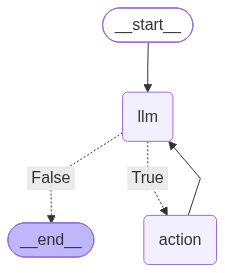

In [12]:
from IPython.display import Image, display

try:
  # A linha que você provavelmente quer tentar primeiro é:
  image_data = abot.graph.get_graph().draw_mermaid_png()
  display(Image(data=image_data))

except Exception as e:
  print(f"Erro ao tentar gerar PNG do Mermaid: {e}")
  print("\nCertifique-se de que a sua versão do LangGraph possui o método `.draw_mermaid_png()`.")
  print("Como alternativa, use `.draw_mermaid()` para obter a string e visualizar externamente.")

## Execução do fluxo de busca (Streaming)

In [18]:
messages = [HumanMessage(content="Como está o tempo em São Paulo Amanhã?")]

In [19]:
print("Iniciando a Iteração com o Agente:")

final_result_state = None

for s in abot.graph.stream({"messages": messages}):
  print(s)
  print('---')
  final_result_state = s


print("\nResultado Final:")

# Verifica se o estado final existe
if final_result_state and 'llm' in final_result_state and final_result_state['llm']['messages']:
  
  # Acessa a lista de mensagens dentrop de 'llm' e pega o conteúdo da última mensagem
  print(final_result_state['llm']['messages'][-1].content)

else:
  print('Nenhum resultado final ou resultado inesperado.')

Iniciando a Iteração com o Agente:
{'llm': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 159, 'total_tokens': 191, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_2b60292592', 'id': 'chatcmpl-Ei3DRfVet8b1fNFosxOnSv3jqkKOk', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1bcb7-6e12-7982-a8e9-fcc181d978e9-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'previsão do tempo São Paulo 22 de outubro de 2023'}, 'id': 'call_19QjCeFFUMJZXouddj8rQBge', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 

In [20]:
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'previsão do tempo São Paulo 22 de outubro de 2023'}, 'id': 'call_zUI6DXpPwU2FvCn0KJ1JE9RP', 'type': 'tool_call'}
Back to the model!


In [22]:
result['messages'][-1].content

'A previsão do tempo para amanhã, 22 de outubro de 2023, em São Paulo indica que o dia será nublado com chuva ocasional. A probabilidade de precipitação é de 70%. Para mais detalhes, você pode conferir a fonte [aqui](https://weathernews.com/news/pt/brazil/2026/10/21/weather-944).'